# Machine Failure Prediction — Predictive Maintenance (CRISP-DM)

**Tujuan:** memprediksi unit mesin yang berisiko gagal *sebelum* kegagalan terjadi,
meminimalkan total biaya maintenance, dan memberi teknisi dugaan **mode kegagalan**.

| CRISP-DM | Isi notebook | Kode produksi |
|---|---|---|
| 1. Business Understanding | biaya, kriteria sukses | `docs/01_business_understanding.md` |
| 2. Data Understanding | audit kualitas, EDA, uji statistik, validasi mekanisme fisik | `pipelines/02_data_understanding.py` |
| 3. Data Preparation | leakage, skema, split terkunci, fitur fisika | `pipelines/03_data_preparation.py`, `src/mfp/features.py` |
| 4. Modeling | repeated CV, ablation, tuning, ensemble, kalibrasi, threshold biaya | `pipelines/04_modeling.py` |
| 5. Evaluation | test + bootstrap CI, dampak bisnis, explainability, error analysis | `pipelines/05_evaluation.py` |
| 6. Deployment | model bundle, REST API, CLI, monitoring drift | `pipelines/06_deployment.py`, `app/` |

> Notebook ini adalah **laporan naratif**: membaca artefak hasil `make all`, sehingga
> angka di sini identik dengan pipeline produksi.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display
from mfp.config import load_config
from mfp.data import load_raw, audit_quality

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
cfg = load_config()
FIG, TAB, MODELS = ROOT / "reports/figures", ROOT / "reports/tables", ROOT / "models"
table = lambda name: pd.read_csv(TAB / f"{name}.csv")

## 1. Business Understanding

* Kegagalan tak terdeteksi (FN) = **10.000** satuan biaya; setiap alarm memicu inspeksi = **500**.
* Rasio 20:1 → threshold Bayes-optimal teoretis ≈ 0,05, **bukan 0,5**.
* Kriteria sukses: PR-AUC ≥ 0,80, recall ≥ 80%, biaya < 50% strategi reaktif & < inspeksi-semua.

## 2. Data Understanding
### 2.1 Sekilas data & audit kualitas

In [2]:
df = load_raw(ROOT / cfg["paths"]["raw_data"])
print(df.shape)
display(df.head())
display(audit_quality(df, cfg).to_frame())

(10000, 14)


,udi,product_id,type,air_temp_k,process_temp_k,rot_speed_rpm,torque_nm,tool_wear_min,machine_failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1000,308.6000,1551,42.8000,0,0,0,0,0,0,0
1,2,L47181,L,298.2000,308.7000,1408,46.3000,3,0,0,0,0,0,0
2,3,L47182,L,298.1000,308.5000,1498,49.4000,5,0,0,0,0,0,0
3,4,L47183,L,298.2000,308.6000,1433,39.5000,7,0,0,0,0,0,0
4,5,L47184,L,298.2000,308.7000,1408,40.0000,9,0,0,0,0,0,0


,Pemeriksaan,Hasil
0,Jumlah baris,10000
1,Baris duplikat,0
2,Sel kosong,0
3,Failure rate,3.39%
4,Failure=1 tanpa mode (UDI),9
5,Mode=1 tetapi failure=0,18
6,Prefix Product ID == Type,100%


**Temuan penting**
* Tidak ada nilai kosong/duplikat; prefix `Product ID` = `Type` (redundan → dibuang).
* **Label anomali**: 9 baris `Machine failure=1` tanpa mode, 18 baris `RNF=1` dengan failure=0.
  Label tidak diubah (ground truth operator); dampaknya dianalisis di error analysis.
* Kolom TWF/HDF/PWF/OSF/RNF = **target leakage** (diketahui setelah kegagalan).

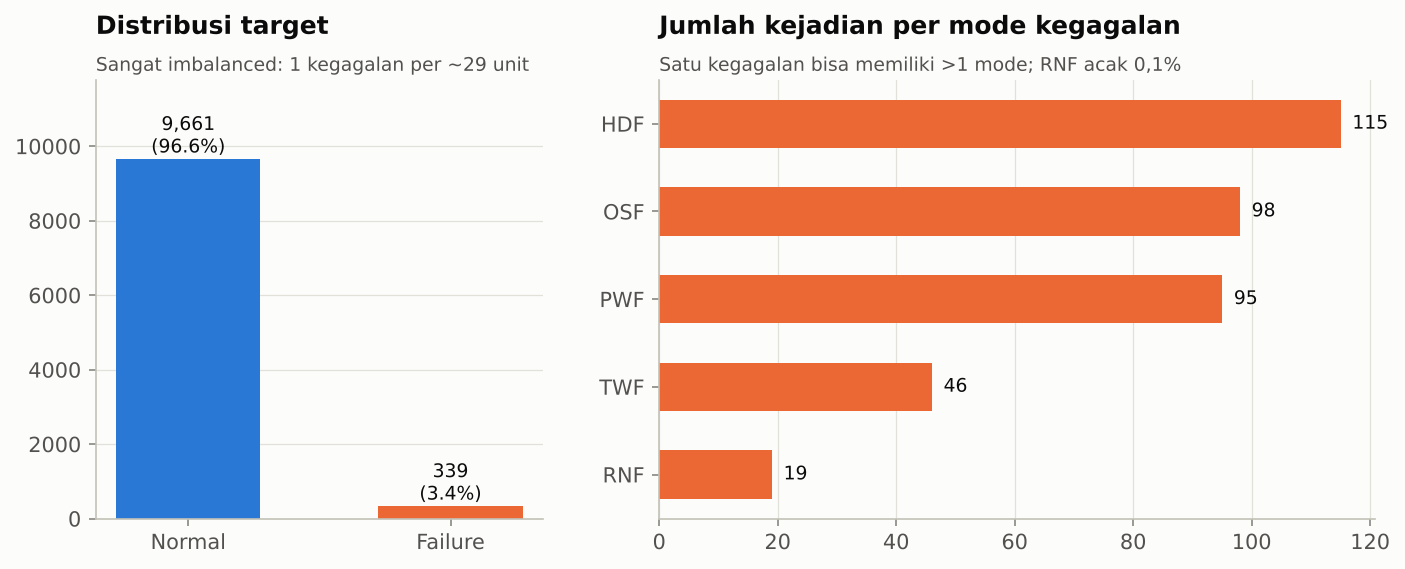

In [3]:
display(Image(filename=str(FIG / "02_target_and_modes.png")))

### 2.2 Sensor mana yang membedakan unit gagal? (Mann-Whitney U + rank-biserial effect size)

,feature,median_failure,median_normal,mann_whitney_p,rank_biserial,effect
0,torque_nm,53.7000,39.9000,0.0000,0.5405,besar
1,rot_speed_rpm,"1,365.0000","1,507.0000",0.0000,-0.5334,besar
2,power_w,"7,611.4297","6,243.0462",0.0000,0.4913,besar
3,strain_minnm,"7,681.8000","3,952.8000",0.0000,0.4089,sedang
4,temp_diff_k,9.3000,9.8000,0.0000,-0.3247,sedang
5,tool_wear_min,165.0000,107.0000,0.0000,0.3242,sedang
6,air_temp_k,301.6000,300.0000,0.0000,0.2655,kecil
7,process_temp_k,310.4000,310.0000,0.0001,0.1274,kecil


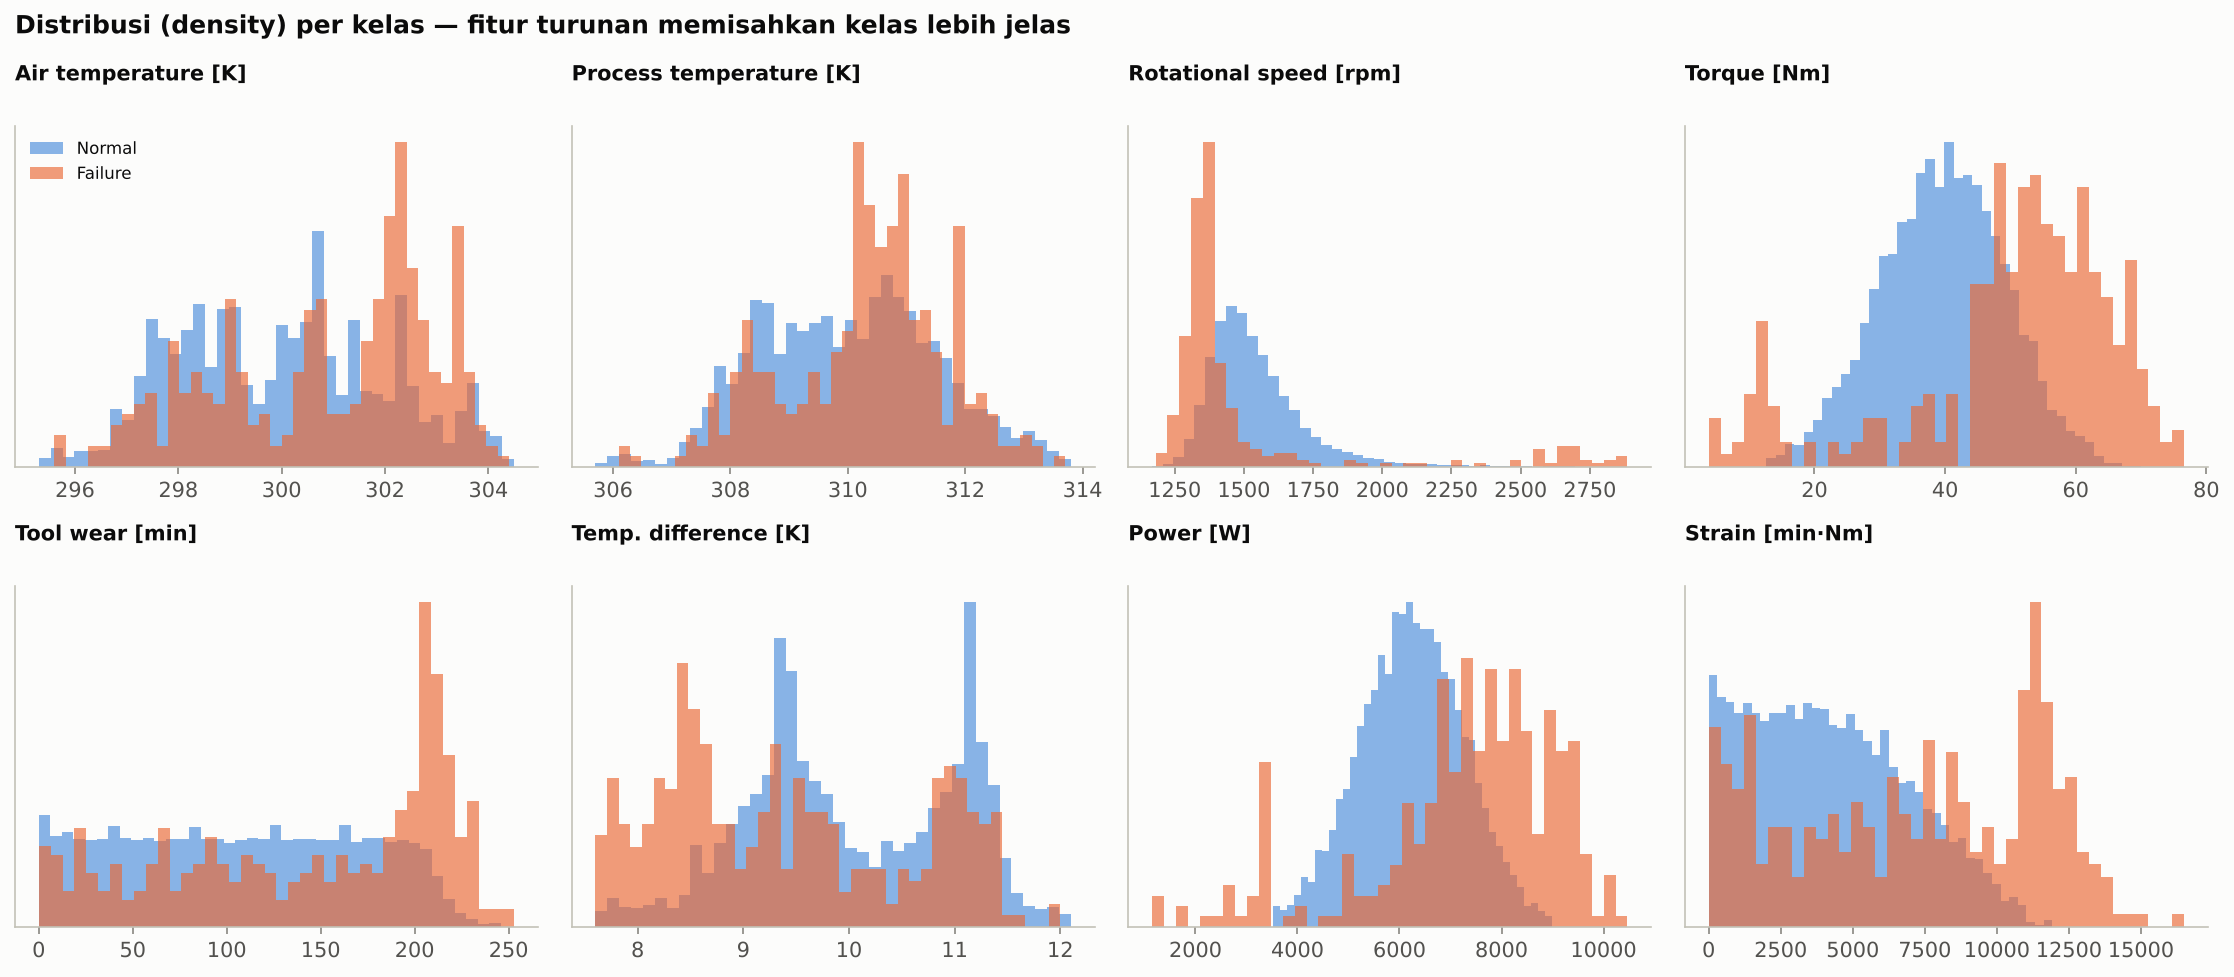

In [4]:
display(table("02_mannwhitney"))
display(Image(filename=str(FIG / "02_distributions_by_class.png")))

### 2.3 Validasi hipotesis mekanisme fisik
Setiap mode kegagalan muncul di wilayah yang dapat dijelaskan fisika — inilah dasar
*feature engineering* di tahap 3.

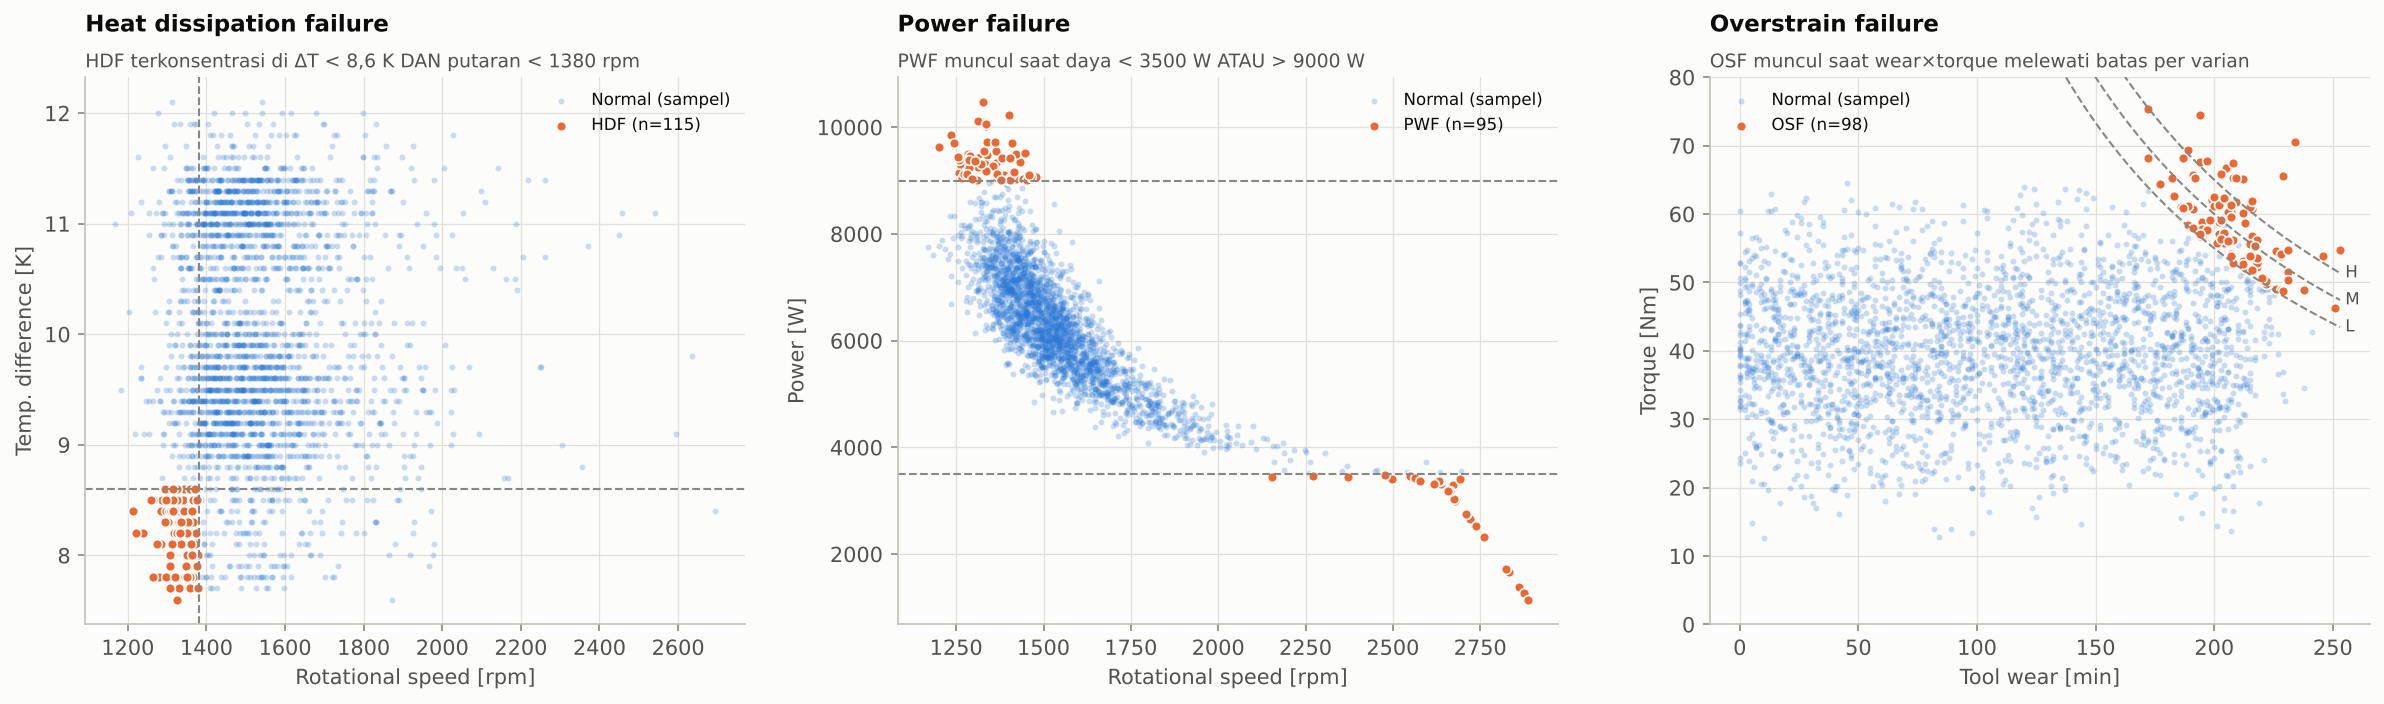

In [5]:
display(Image(filename=str(FIG / "02_physics_mechanisms.png")))

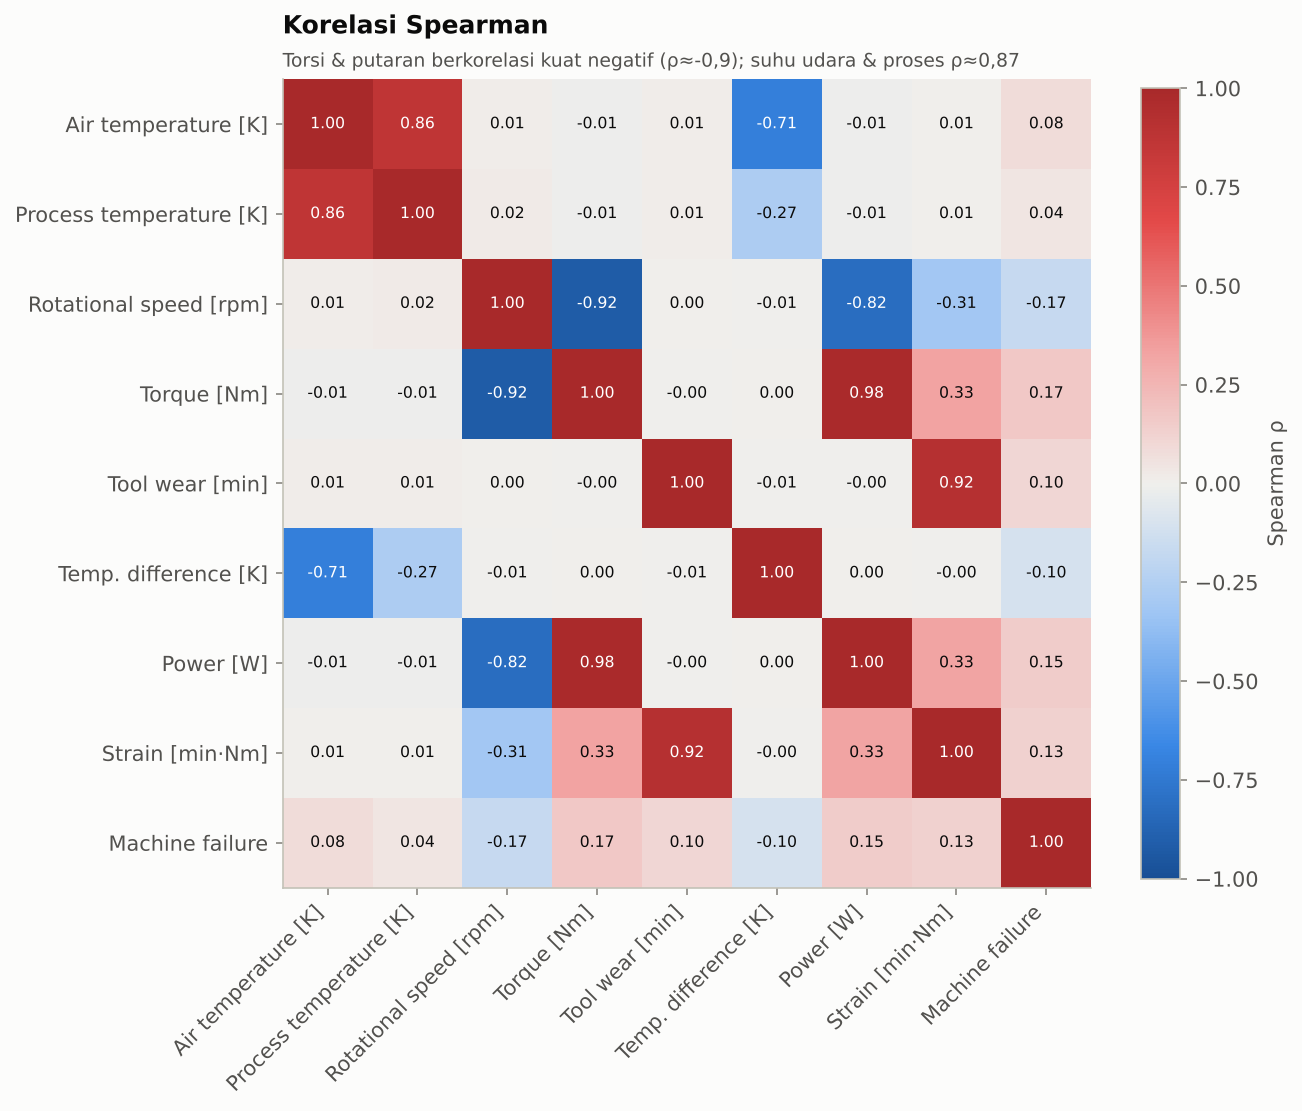

In [6]:
display(Image(filename=str(FIG / "02_correlation.png")))

## 3. Data Preparation

* Fitur: hanya 6 kolom yang tersedia **sebelum** kegagalan (`type` + 5 sensor).
* Validasi skema eksplisit (`mfp.data.validate_features`) dipakai saat training **dan** serving.
* Split stratified 80/20 dikunci ke disk; test set tidak disentuh sampai tahap 5.
* Fitur fisika dibuat **di dalam** `sklearn.Pipeline` → di-fit ulang per fold, tanpa
  training-serving skew.

In [7]:
print(json.dumps(json.loads((ROOT / "data/processed/data_manifest.json").read_text()), indent=2))

from mfp.features import PhysicsFeatures
sample = df[["type", *cfg["features"]["numeric_raw"]]].head(3)
display(PhysicsFeatures(overstrain_limits=cfg["features"]["overstrain_limits"]).fit_transform(sample))

{
  "created_utc": "2026-11-09T16:23:05+00:00",
  "raw_file": "data/raw/machine_failure.csv",
  "raw_md5": "f0adaa9c5e25366c6df1cc2684479871",
  "random_state": 42,
  "test_size": 0.2,
  "n_train": 8000,
  "n_test": 2000,
  "failures_train": 271,
  "failures_test": 68,
  "failure_rate_train": 0.03388,
  "failure_rate_test": 0.034,
  "feature_columns": [
    "type",
    "air_temp_k",
    "process_temp_k",
    "rot_speed_rpm",
    "torque_nm",
    "tool_wear_min"
  ],
  "excluded_leakage_columns": [
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
  ]
}


,type,air_temp_k,process_temp_k,rot_speed_rpm,torque_nm,tool_wear_min,temp_diff_k,power_w,strain_minnm,strain_ratio,torque_per_krpm,wear_fraction
0,M,298.1000,308.6000,1551,42.8000,0,10.5000,"6,951.5906",0.0000,0.0000,27.5951,0.0000
1,L,298.2000,308.7000,1408,46.3000,3,10.5000,"6,826.7227",138.9000,0.0126,32.8835,0.0125
2,L,298.1000,308.5000,1498,49.4000,5,10.4000,"7,749.3875",247.0000,0.0225,32.9773,0.0208


## 4. Modeling
### 4.1 Perbandingan model × set fitur (repeated stratified 5-fold × 3, hanya data train)
Uji signifikansi memakai **corrected resampled t-test** (Nadeau & Bengio) karena skor
fold CV tidak independen.

,model,features,pr_auc_mean,pr_auc_std,roc_auc_mean,fit_time_s,p_vs_best
0,Histogram Gradient Boosting,physics,0.9041,0.0228,0.9780,1.6102,NaN
1,Random Forest,physics,0.8966,0.0252,0.9781,2.2193,0.4578
2,Histogram Gradient Boosting,raw,0.8096,0.0313,0.9723,1.2644,0.0000
3,Random Forest,raw,0.7498,0.0435,0.9689,1.6512,0.0000
4,Logistic Regression + Splines (GAM-like),physics,0.6455,0.0511,0.9625,0.0694,0.0000
5,Logistic Regression + Splines (GAM-like),raw,0.5783,0.0621,0.9516,0.0314,0.0000
6,Logistic Regression,physics,0.4482,0.0575,0.9240,0.0415,0.0000
7,Logistic Regression,raw,0.4424,0.0576,0.8985,0.0201,0.0000
8,Dummy (prior),physics,0.0339,0.0003,0.5000,0.0136,0.0000
9,Dummy (prior),raw,0.0339,0.0003,0.5000,0.0090,0.0000


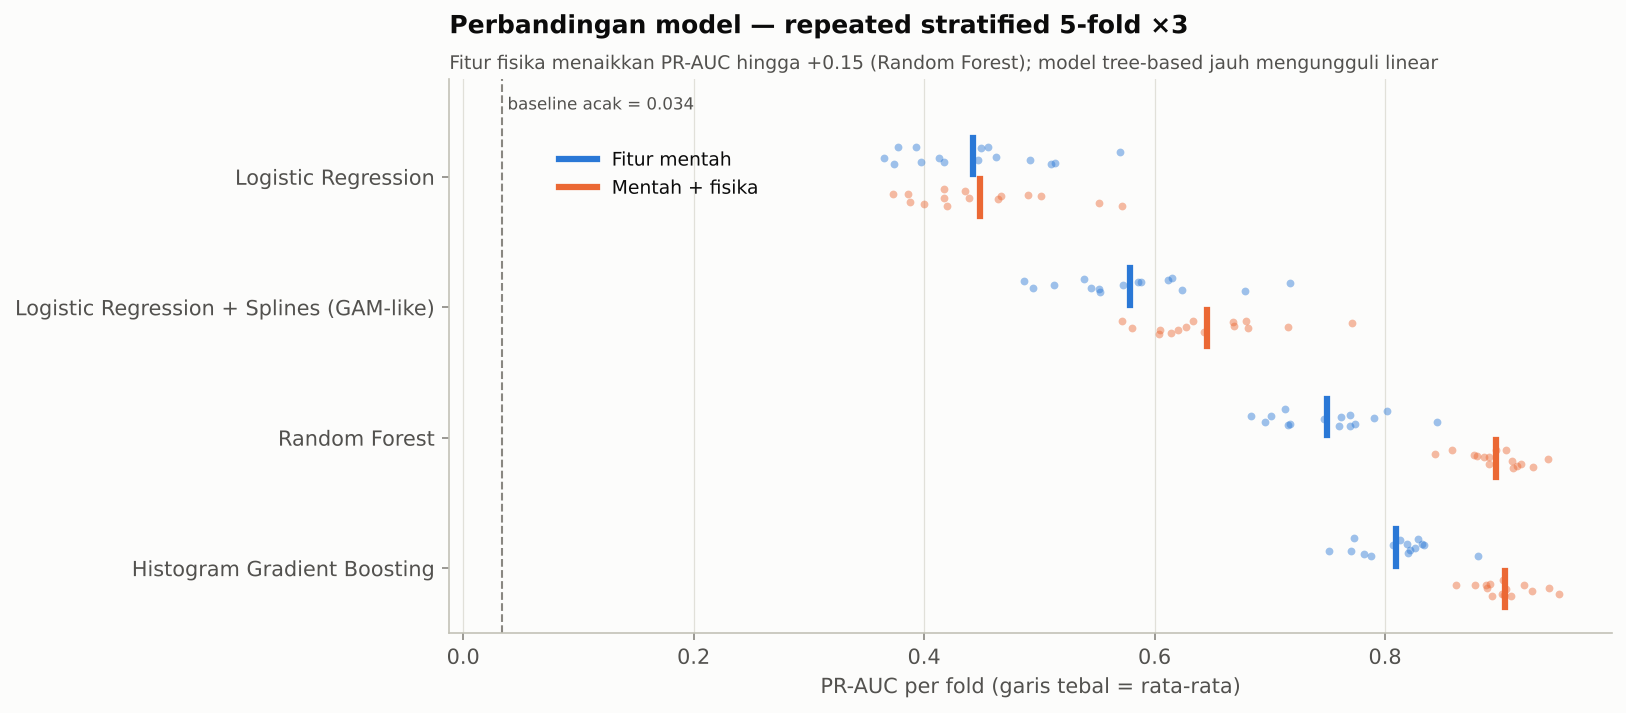

In [8]:
display(table("04_model_comparison"))
display(Image(filename=str(FIG / "04_model_comparison.png")))

### 4.2 Ablation: apakah fitur fisika benar-benar membantu?

In [9]:
display(table("04_feature_ablation"))

,model,pr_auc_raw,pr_auc_physics,delta,p_value
0,Logistic Regression,0.4424,0.4482,0.0057,0.8018
1,Logistic Regression + Splines (GAM-like),0.5783,0.6455,0.0673,0.0015
2,Random Forest,0.7498,0.8966,0.1469,0.0000
3,Histogram Gradient Boosting,0.8096,0.9041,0.0945,0.0000


Fitur fisika menaikkan PR-AUC Random Forest **+0,15** dan gradient boosting **+0,09**
(signifikan, p < 0,001). Domain knowledge > model yang lebih kompleks.

### 4.3 Model tuned (prediksi out-of-fold) & ensemble

In [10]:
display(table("04_oof_tuned"))
print(json.dumps(json.loads((MODELS / "training_summary.json").read_text()), indent=2))

{
  "final_model": "random_forest",
  "final_model_label": "Random Forest",
  "ensemble_members": [],
  "calibration": "none",
  "threshold": 0.025,
  "oof_pr_auc": 0.9106494954746085,
  "oof_roc_auc": 0.9791170838348312,
  "oof_brier": 0.006348020457496099,
  "best_params": {
    "model__class_weight": null,
    "model__max_depth": 8,
    "model__max_features": 0.7,
    "model__min_samples_leaf": 7,
    "model__n_estimators": 500
  },
  "mode_labels": [
    "TWF",
    "HDF",
    "PWF",
    "OSF"
  ],
  "cv": {
    "n_splits": 5,
    "n_repeats": 3,
    "search_iter": 25
  },
  "cost": {
    "fn": 10000,
    "fp": 500,
    "min_recall": 0.8
  },
  "runtime_min": 14.9
}


,model,oof_pr_auc,oof_roc_auc,oof_brier
0,Soft-voting ensemble,0.9149,0.9800,0.0057
1,Random Forest,0.9106,0.9791,0.0063
2,Histogram Gradient Boosting,0.8990,0.9758,0.0061
3,Logistic Regression + Splines (GAM-like),0.6835,0.9630,0.0534
4,Logistic Regression,0.4756,0.9249,0.1089


Soft-voting ensemble hanya +0,004 PR-AUC di atas Random Forest → **di bawah ambang +0,005**,
jadi model tunggal dipilih (parsimoni: lebih cepat, lebih mudah dijelaskan & dirawat).

### 4.4 Kalibrasi & 4.5 threshold berbasis biaya

,calibration,oof_brier,oof_pr_auc,mean_pred,observed_rate
0,none,0.0063,0.9106,0.0337,0.0339
1,sigmoid,0.0084,0.8812,0.0299,0.0339
2,isotonic,0.0071,0.8964,0.0343,0.0339


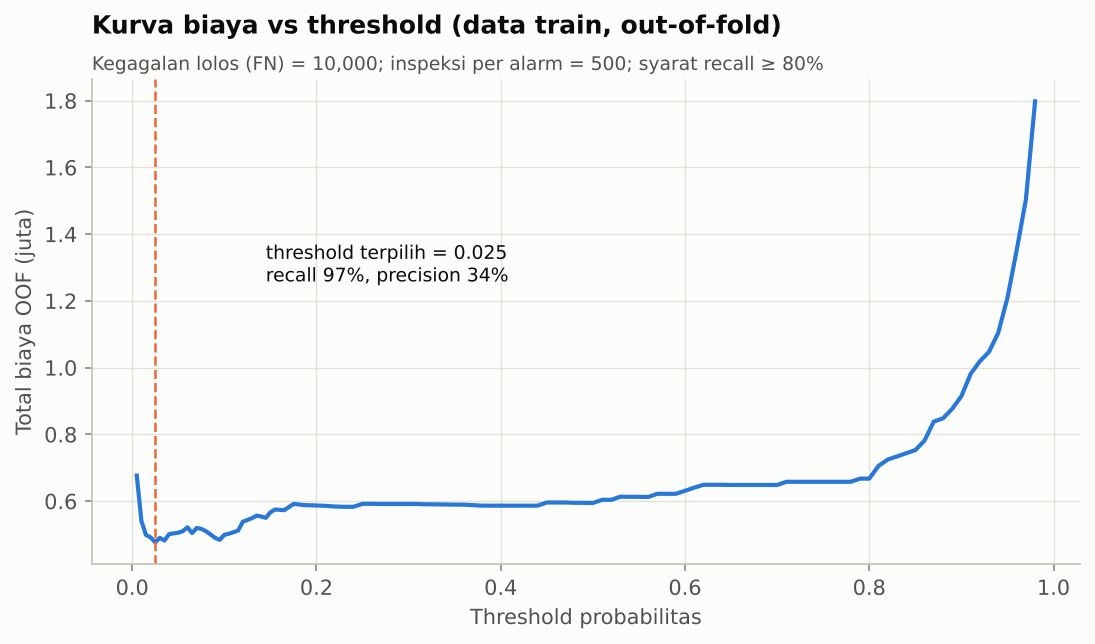

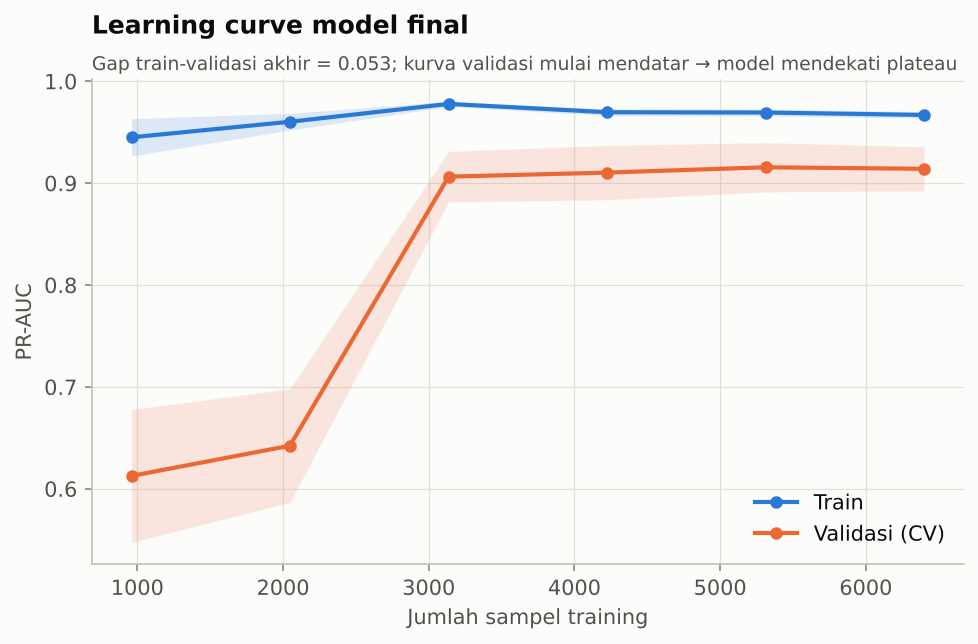

In [11]:
display(table("04_calibration"))
display(Image(filename=str(FIG / "04_cost_curve_oof.png")))
display(Image(filename=str(FIG / "04_learning_curve.png")))

## 5. Evaluation (test set terkunci, dipakai sekali)
### 5.1 Metrik + 95% bootstrap CI

,Unnamed: 0,pr_auc,roc_auc,brier,recall,precision,f1,f2,mcc,specificity,tp,fp,fn,tn,expected_cost
0,threshold 0.50,0.9055,0.9786,0.0065,0.7794,0.9636,0.8618,0.8104,0.8626,0.9990,53.0000,2.0000,15.0000,"1,930.0000","177,500.0000"
1,threshold biaya 0.025,0.9055,0.9786,0.0065,0.9559,0.3155,0.4745,0.6799,0.5264,0.9270,65.0000,141.0000,3.0000,"1,791.0000","133,000.0000"


,Unnamed: 0,estimate,ci_low,ci_high
0,pr_auc,0.9055,0.8393,0.9596
1,roc_auc,0.9786,0.9545,0.9968
2,recall,0.9559,0.8971,1.0000
3,precision,0.3155,0.2819,0.3536
4,f2,0.6799,0.6328,0.7234
5,mcc,0.5264,0.4834,0.5676


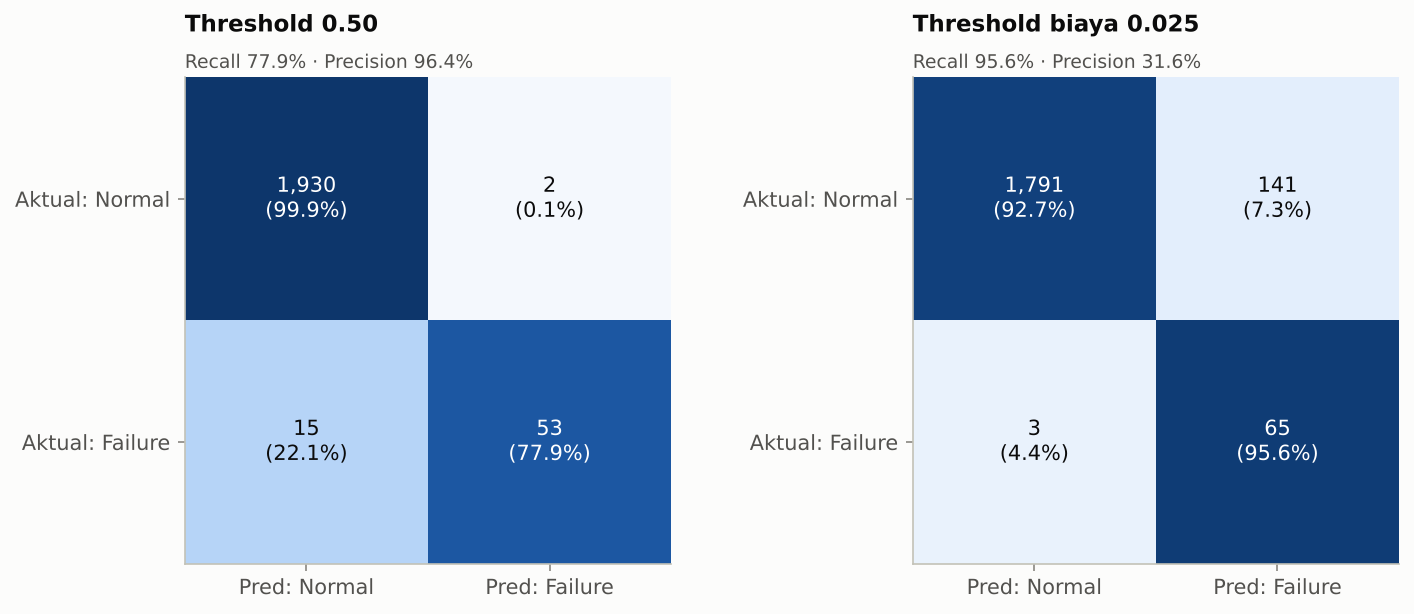

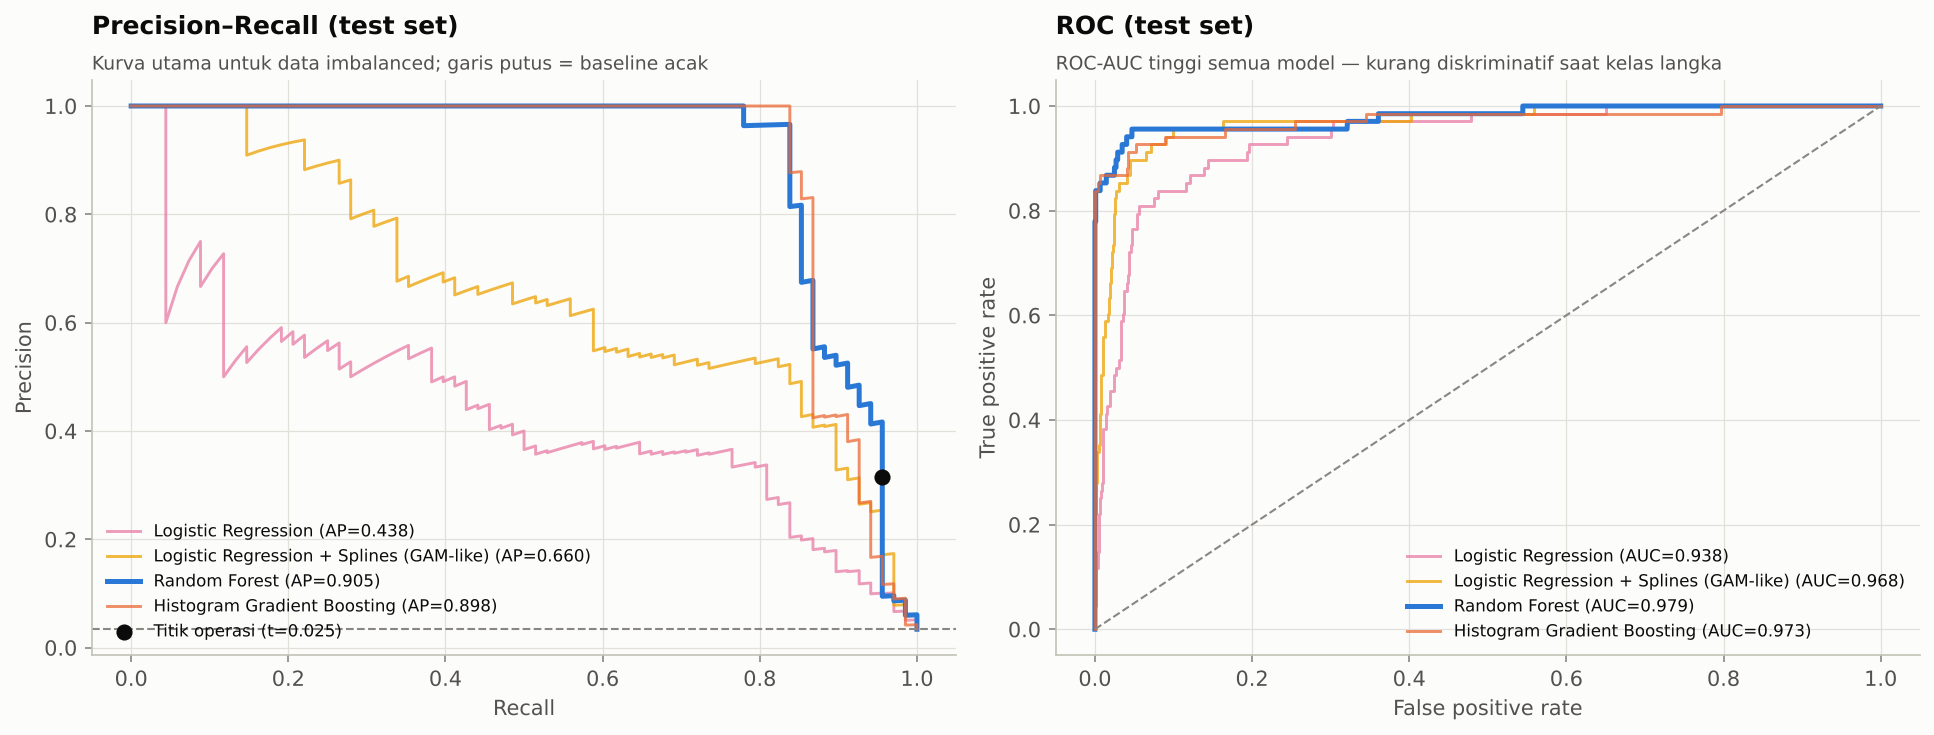

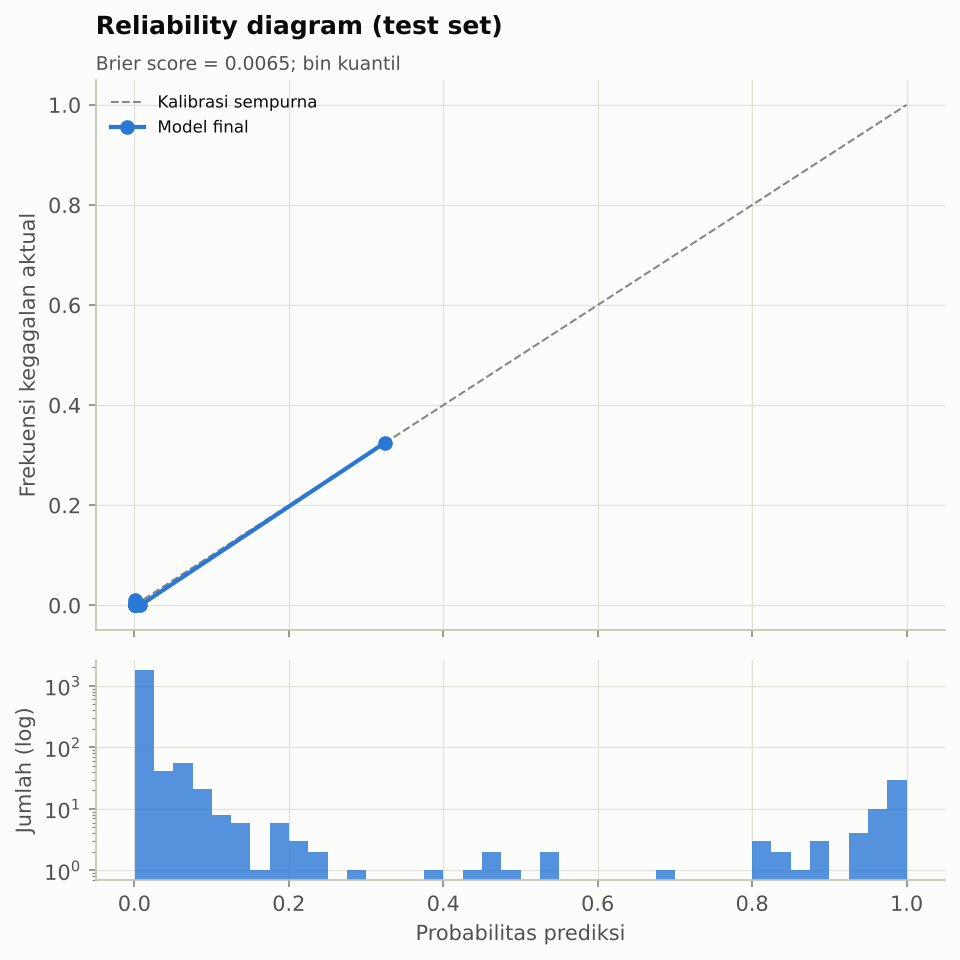

In [12]:
display(pd.read_csv(TAB / "05_test_metrics.csv"))
display(pd.read_csv(TAB / "05_test_metrics_ci.csv"))
display(Image(filename=str(FIG / "05_confusion_matrices.png")))
display(Image(filename=str(FIG / "05_pr_roc_curves.png")))
display(Image(filename=str(FIG / "05_calibration.png")))

### 5.2 Dampak bisnis

,strategi,biaya,kegagalan_lolos,inspeksi,penghematan_vs_reaktif
0,Reaktif (run-to-failure),"680,000.0000",68,0,0.0000
1,Inspeksi semua unit,"1,000,000.0000",0,2000,-0.4706
2,Model @ threshold 0.50,"177,500.0000",15,55,0.7390
3,Model @ threshold biaya,"133,000.0000",3,206,0.8044


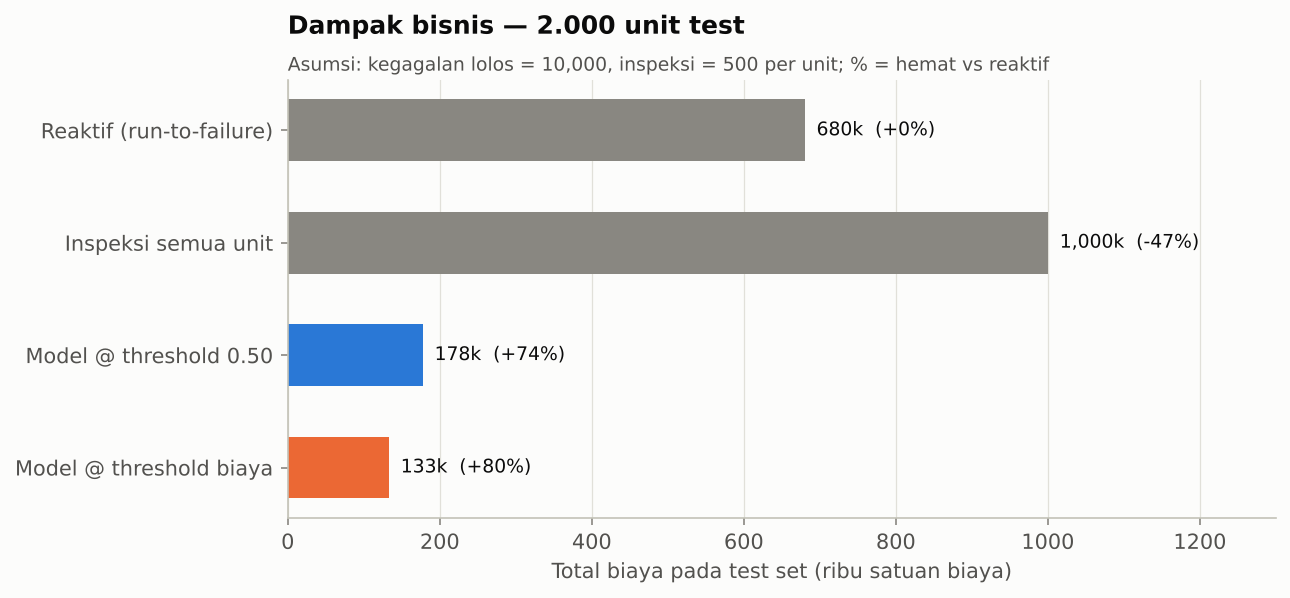

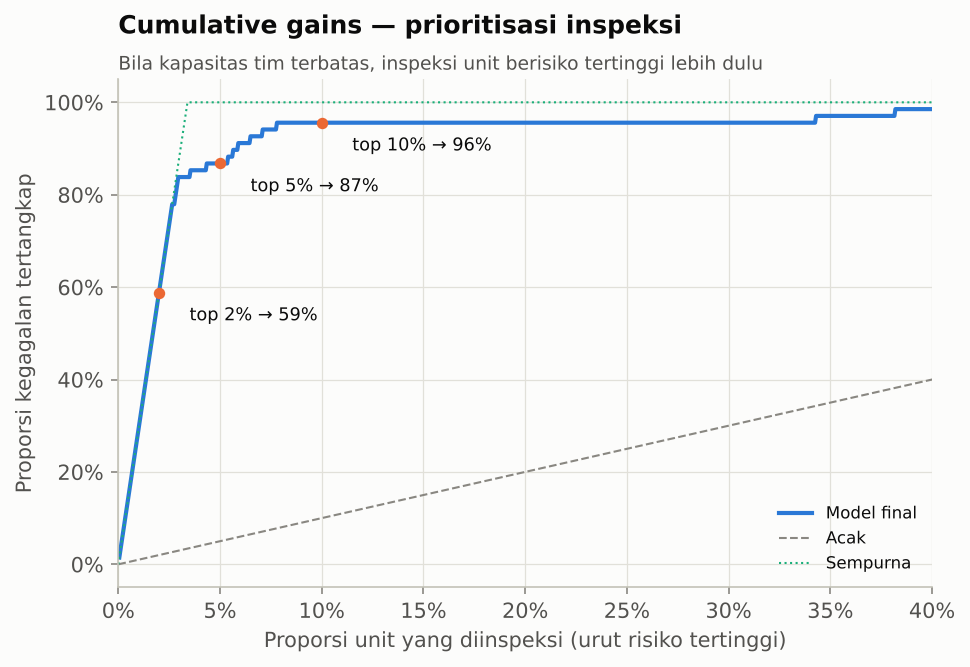

In [13]:
display(table("05_business_impact"))
display(Image(filename=str(FIG / "05_business_impact.png")))
display(Image(filename=str(FIG / "05_cumulative_gains.png")))

### 5.3 Explainability — apakah model belajar mekanisme yang benar?

Surrogate decision tree (depth 4) — fidelity terhadap keputusan model final (threshold 0.025) pada test set: 98.05%
Satuan fisik asli: K, rpm, Nm, min, W, min·Nm; strain_ratio = strain / batas varian.

|--- wear_fraction <= 0.8
|   |--- power_w <= 8904.6
|   |   |--- power_w <= 3550.6
|   |   |   |--- class: 1
|   |   |--- power_w >  3550.6
|   |   |   |--- strain_minnm <= 10972.2
|   |   |   |   |--- class: 0
|   |   |   |--- strain_minnm >  10972.2
|   |   |   |   |--- class: 1
|   |--- power_w >  8904.6
|   |   |--- power_w <= 9035.5
|   |   |   |--- class: 1
|   |   |--- power_w >  9035.5
|   |   |   |--- class: 1
|--- wear_fraction >  0.8
|   |--- wear_fraction <= 0.9
|   |   |--- air_temp_k <= 300.4
|   |   |   |--- class: 1
|   |   |--- air_temp_k >  300.4
|   |   |   |--- class: 1
|   |--- wear_fraction >  0.9
|   |   |--- wear_fraction <= 0.9
|   |   |   |--- class: 1
|   |   |--- wear_fraction >  0.9
|   |   |   |--- class: 1



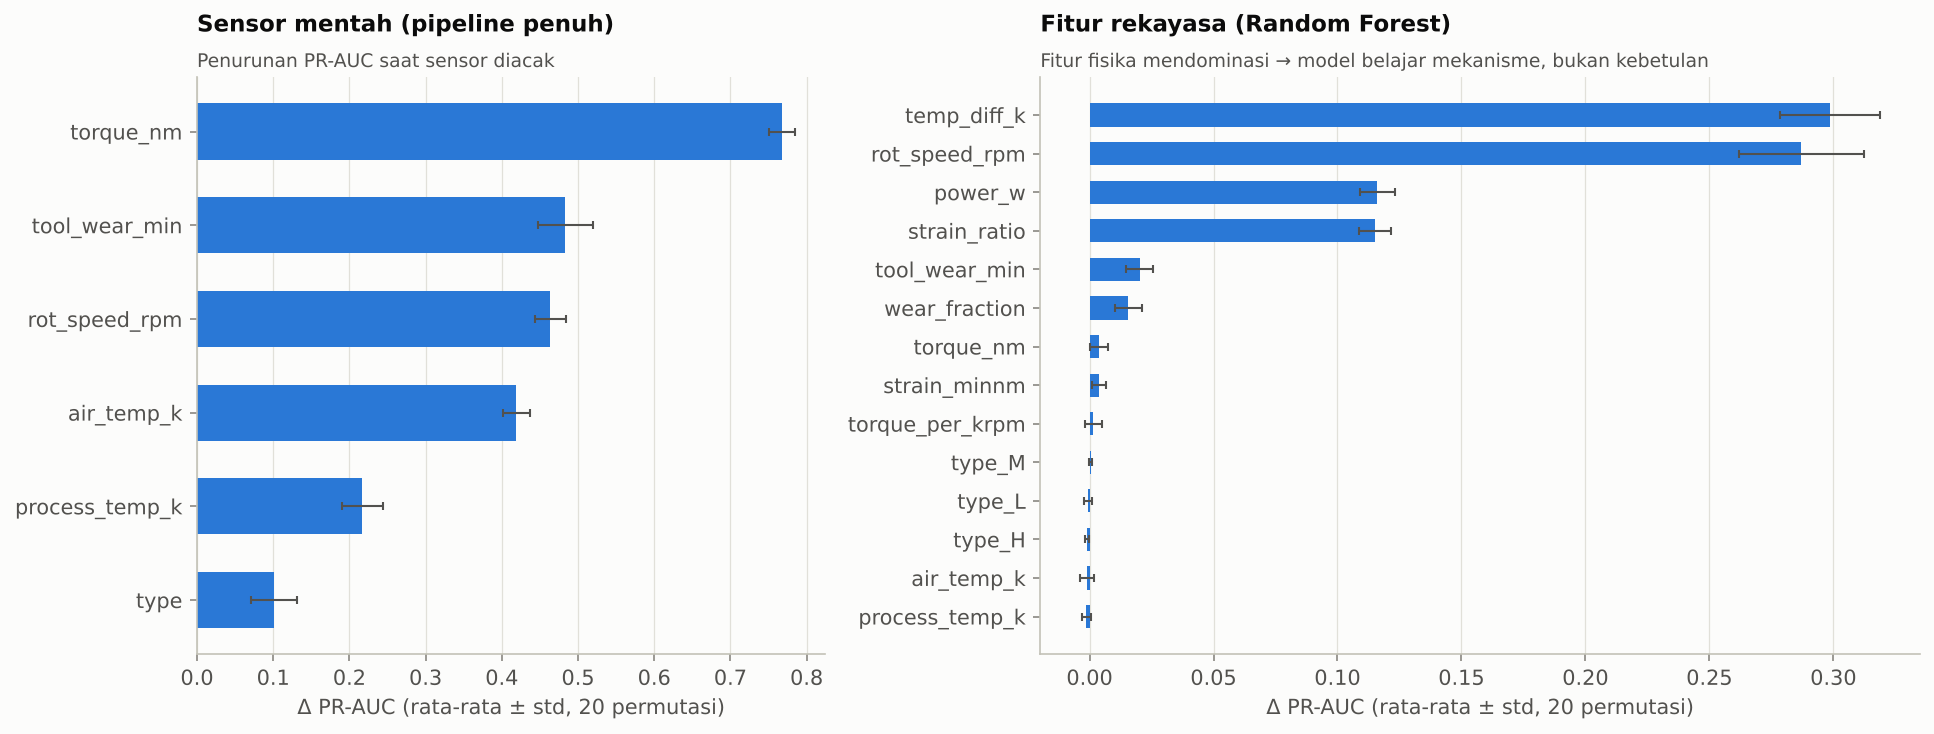

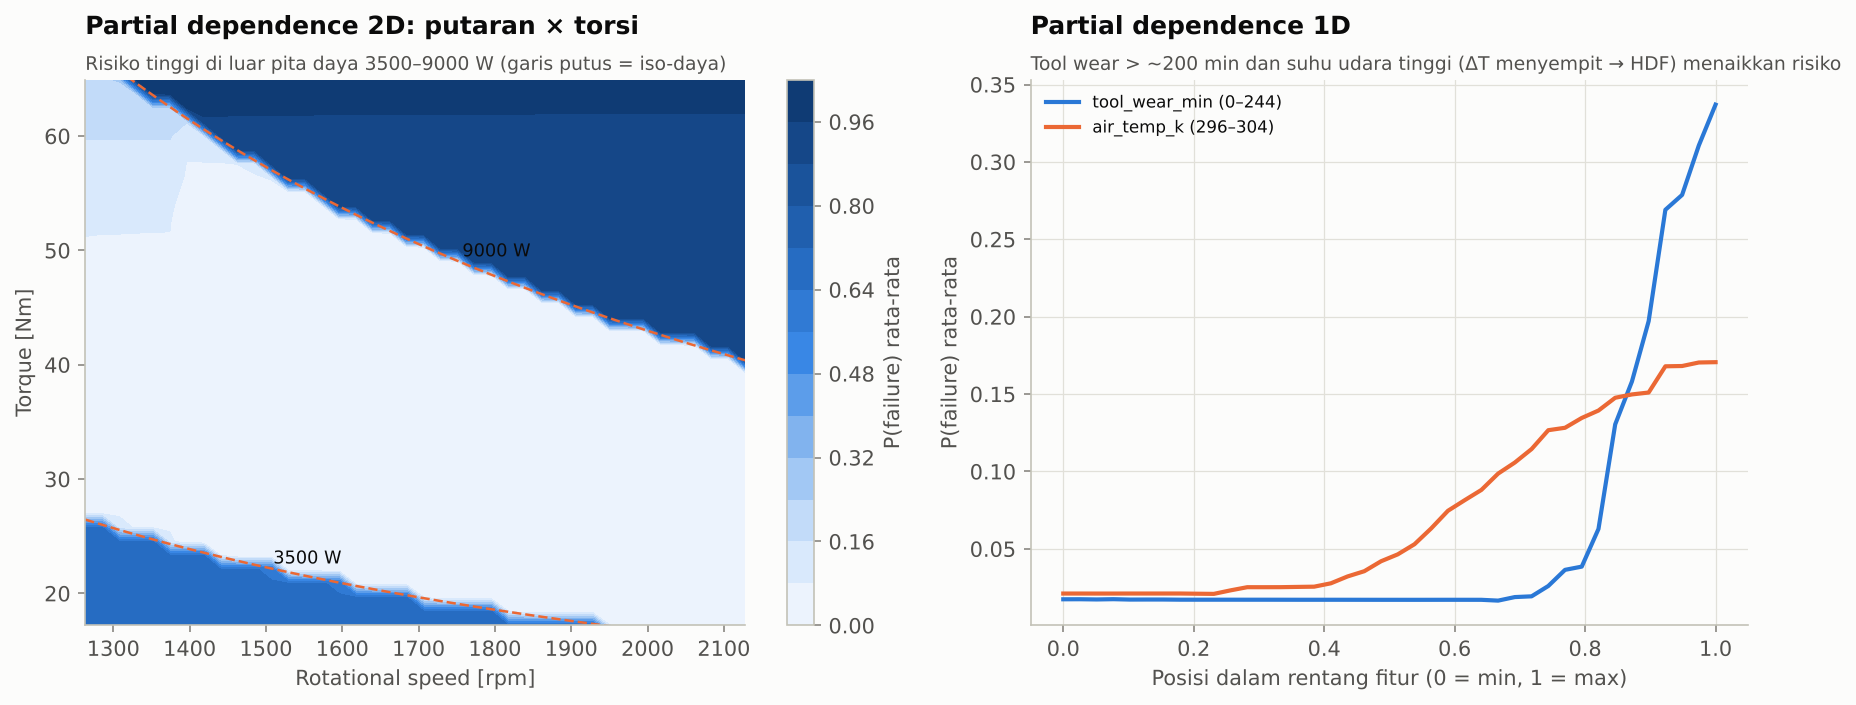

In [14]:
display(Image(filename=str(FIG / "05_permutation_importance.png")))
display(Image(filename=str(FIG / "05_partial_dependence.png")))
print((TAB / "05_surrogate_rules.txt").read_text())

Pohon surrogate (fidelity ~98%) **menemukan kembali** aturan fisika tanpa diberi tahu:
daya < ~3.550 W atau > ~8.900 W (PWF), strain > ~11.000 min·Nm (OSF), dan keausan
tool > ~80% umur (TWF). Partial dependence 2D menunjukkan pita daya aman 3.500–9.000 W.

### 5.4 Error analysis per mode kegagalan

,mode,n_test,terdeteksi,recall,median_proba
0,TWF,10,8,0.8000,0.0713
1,HDF,29,29,1.0000,0.9428
2,PWF,13,13,1.0000,0.9910
3,OSF,16,16,1.0000,0.9977
4,tanpa mode,2,1,0.5000,0.0270


,udi,type,air_temp_k,process_temp_k,rot_speed_rpm,torque_nm,tool_wear_min,mode,proba
0,1997,M,298.4000,308.0000,1416,38.2000,198,TWF,0.0007
1,8507,L,298.4000,309.6000,1710,27.3000,163,tanpa mode,0.0011
2,9175,L,297.8000,308.9000,1871,25.6000,200,TWF,0.0012


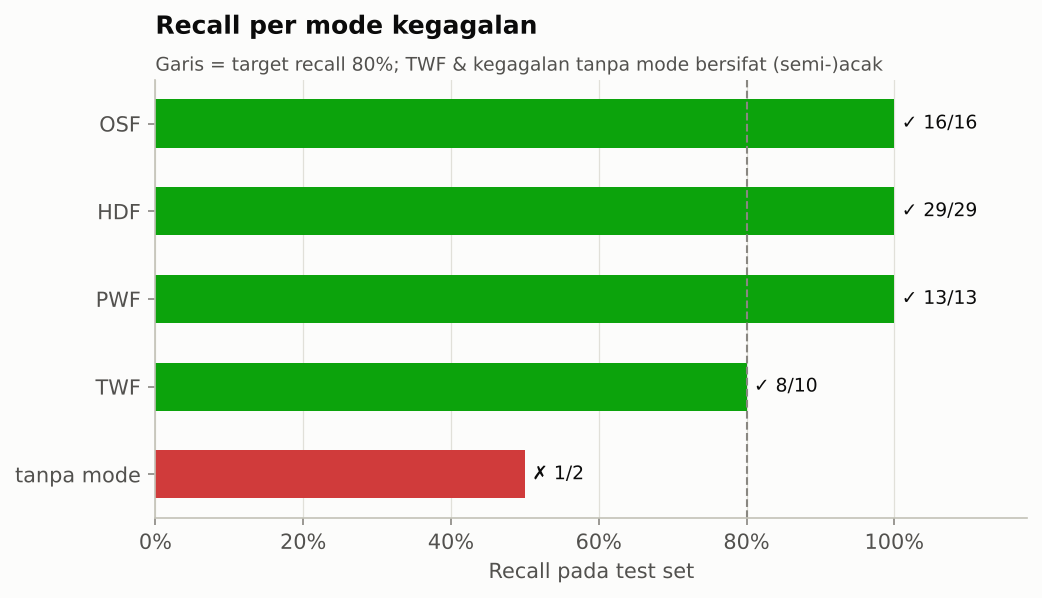

,mode,n_test,pr_auc,roc_auc
0,TWF,10,0.0701,0.9086
1,HDF,29,0.9507,0.9994
2,PWF,13,1.0000,1.0000
3,OSF,16,1.0000,1.0000


In [15]:
display(table("05_recall_by_mode"))
display(table("05_false_negatives"))
display(Image(filename=str(FIG / "05_recall_by_mode.png")))
display(table("05_mode_model_test"))

Kegagalan yang lolos adalah **TWF** (acak di rentang keausan 200–240 min) dan satu
kegagalan **tanpa mode** — keduanya secara desain tidak dapat diprediksi dari snapshot sensor.

## 6. Deployment
### 6.1 Scoring skenario dengan model bundle

In [16]:
from mfp.inference import ModelBundle
bundle = ModelBundle.load(MODELS / "model_bundle.joblib")
scenarios = pd.DataFrame([
    dict(skenario="Operasi normal",           type="M", air_temp_k=300.0, process_temp_k=310.0, rot_speed_rpm=1500, torque_nm=40.0, tool_wear_min=50),
    dict(skenario="Daya berlebih (PWF)",      type="L", air_temp_k=300.5, process_temp_k=310.5, rot_speed_rpm=1300, torque_nm=70.0, tool_wear_min=60),
    dict(skenario="Pendinginan buruk (HDF)",  type="L", air_temp_k=302.8, process_temp_k=310.9, rot_speed_rpm=1330, torque_nm=48.0, tool_wear_min=90),
    dict(skenario="Overstrain (OSF)",         type="L", air_temp_k=300.0, process_temp_k=310.0, rot_speed_rpm=1400, torque_nm=55.0, tool_wear_min=215),
    dict(skenario="Tool hampir habis (TWF?)", type="H", air_temp_k=299.0, process_temp_k=309.5, rot_speed_rpm=1600, torque_nm=35.0, tool_wear_min=225),
])
res = scenarios[["skenario"]].join(bundle.predict(scenarios.drop(columns="skenario")))
display(res[["skenario", "failure_probability", "risk_level", "likely_failure_mode", "recommended_action"]])

,skenario,failure_probability,risk_level,likely_failure_mode,recommended_action
0,Operasi normal,0.0004,LOW,-,Operasi normal — lanjutkan monitoring rutin.
1,Daya berlebih (PWF),0.9988,HIGH,PWF,Inspeksi segera / pertimbangkan menghentikan unit.
2,Pendinginan buruk (HDF),0.9853,HIGH,HDF,Inspeksi segera / pertimbangkan menghentikan unit.
3,Overstrain (OSF),1.0000,HIGH,OSF,Inspeksi segera / pertimbangkan menghentikan unit.
4,Tool hampir habis (TWF?),0.1953,MEDIUM,TWF,Jadwalkan inspeksi pada jendela maintenance berikutnya.


### 6.2 Validasi level risiko & monitoring drift

,risk_level,n_unit,n_failure,failure_rate
0,LOW,1794,3,0.0017
1,MEDIUM,151,12,0.0795
2,HIGH,55,53,0.9636


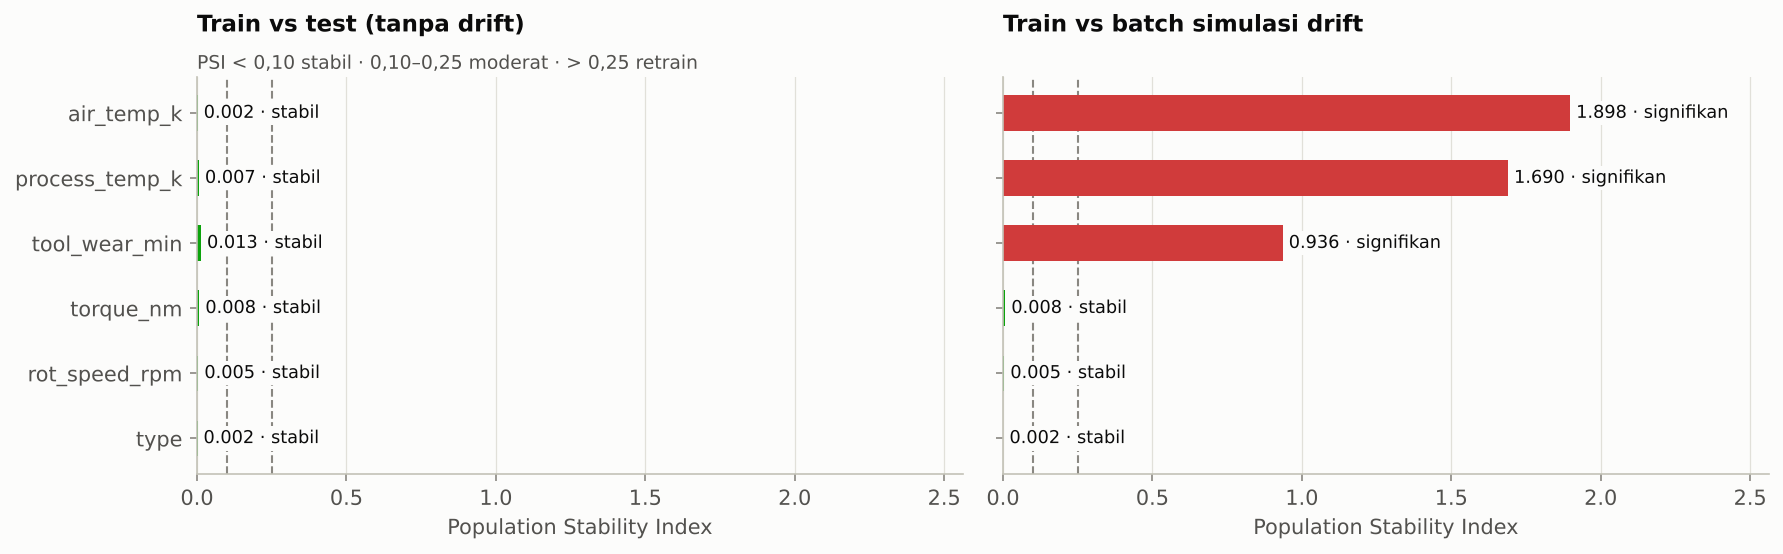

In [17]:
display(table("06_risk_band_validation"))
display(Image(filename=str(FIG / "06_drift_monitoring.png")))

## 7. Kesimpulan

* **Random Forest + fitur fisika** mencapai PR-AUC test 0,906 (CI 0,84–0,96), recall 95,6%,
  dan menghemat **~80% biaya** dibanding strategi reaktif.
* Inspeksi 5% unit berisiko tertinggi saja sudah menangkap ~87% kegagalan.
* Model dapat dijelaskan: aturan yang ia pelajari sesuai fisika mesin.
* Level risiko tervalidasi: HIGH ≈ 96% benar-benar gagal, LOW ≈ 0,2%.

**Langkah berikutnya:** data deret waktu untuk *remaining useful life*, shadow deployment
di lini nyata, retraining terjadwal saat PSI > 0,25, dan biaya aktual dari CMMS perusahaan.